# Monocular depth: Depth Anything V2 vs sensor depth

A monocular model predicts depth from
a single RGB image — but a *relative* model outputs values defined only up to an
unknown scale and shift, so they cannot be compared with sensor metres directly.
This notebook:

1. runs **Depth Anything V2** over the SUN RGB-D test split;
2. verifies what the raw output actually represents (disparity vs depth);
3. implements and compares **three scale-alignment methods**;
4. reports standard depth metrics (RMSE, AbsRel, δ<1.25) against sensor depth;
5. contrasts **per-image alignment** (oracle, needs GT at test time) with a single
   **global alignment** fitted once on validation (deployable);
6. breaks the error down by sensor, distance and object size, and saves aligned
   metric depth maps for the point-cloud comparison (also for the 157 extra
   test images of the 20-class split, last section);
7. evaluates the **metric indoor variants** of Depth Anything V2 (Hypersim
   fine-tune, metres out of the box) on the same protocol — is alignment still
   needed, and which sensor-free configuration is the most accurate?

In [1]:
import json, sys, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from PIL import Image
from transformers import AutoImageProcessor, AutoModelForDepthEstimation

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

import utils.sunrgbd as sd

DEVICE = "mps" if torch.backends.mps.is_available() else "cpu"
print(f"torch {torch.__version__}, device: {DEVICE}")

/Users/polina_sushko/miniforge3/envs/env_for_tests/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


torch 2.12.1, device: mps


In [2]:
DATASET_ROOT = Path("/Users/polina_sushko/My_work/University/ВКР/SUNRGBD")
SPLIT_DIR    = Path("outputs/splits")               # std10 config
OUT_DIR      = Path("outputs/depth_mono")
MODEL_ID     = "depth-anything/Depth-Anything-V2-Small-hf"

N_EVAL      = None   # test images for metrics (None = all 1287)
N_FIT_PER_SENSOR = 50  # validation images PER SENSOR used to fit the global alignments
N_SAVE      = None   # test images whose aligned maps are stored as .npy (None = all)
MAX_DEPTH   = sd.MAX_DEPTH_M          # 8 m — sensor range, also used for clipping
MIN_DEPTH   = 0.3                     # m; below this sensor depth is unreliable
EPS         = 1e-6

MAP_DIR = OUT_DIR / "maps"                  # per-image lstsq_disp (oracle)
MAP_DIR_GLOBAL = OUT_DIR / "maps_global"    # global lstsq_disp (deployable)
MAP_DIR.mkdir(parents=True, exist_ok=True)
MAP_DIR_GLOBAL.mkdir(parents=True, exist_ok=True)

with open(SPLIT_DIR / "instances_test.json") as f:
    test_images = json.load(f)["images"]
with open(SPLIT_DIR / "instances_val.json") as f:
    val_images = json.load(f)["images"]
test_images.sort(key=lambda im: im["id"])
val_images.sort(key=lambda im: im["id"])

print(f"test: {len(test_images)} images, val: {len(val_images)} images")
print(f"model: {MODEL_ID}")

test: 1287 images, val: 1284 images
model: depth-anything/Depth-Anything-V2-Small-hf


In [3]:
processor = AutoImageProcessor.from_pretrained(MODEL_ID)
model = AutoModelForDepthEstimation.from_pretrained(MODEL_ID).to(DEVICE).eval()
n_params = sum(p.numel() for p in model.parameters())
print(f"Loaded {MODEL_ID}: {n_params / 1e6:.1f}M parameters on {DEVICE}")


def predict_raw(img_info: dict) -> np.ndarray:
    """Runs the monocular model, returns its raw output at original resolution."""
    image = Image.open(DATASET_ROOT / img_info["file_name"]).convert("RGB")
    inputs = processor(images=image, return_tensors="pt").to(DEVICE)
    with torch.no_grad():
        outputs = model(**inputs)
    post = processor.post_process_depth_estimation(
        outputs, target_sizes=[(img_info["height"], img_info["width"])])
    depth = post[0]["predicted_depth"].cpu().numpy().astype(np.float32)
    # release the MPS cache: over a 1300-image loop the allocator otherwise grows
    # until the machine swaps, and throughput collapses by two orders of magnitude
    del inputs, outputs, post
    if DEVICE == "mps":
        torch.mps.empty_cache()
    return depth


def load_gt(img_info: dict) -> np.ndarray:
    """Sensor depth in metres (0 = invalid)."""
    return sd.read_depth(DATASET_ROOT / img_info["depth_file"])


def valid_mask(gt: np.ndarray) -> np.ndarray:
    """Pixels with usable sensor depth — the only ones any metric may use."""
    return (gt > MIN_DEPTH) & (gt < MAX_DEPTH) & np.isfinite(gt)

Loading weights:   0%|          | 0/287 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 287/287 [00:00<00:00, 6972.08it/s]

Loaded depth-anything/Depth-Anything-V2-Small-hf: 24.8M parameters on mps


---
## What does the raw output represent?

Relative monocular models of the MiDaS/Depth Anything family are trained on
**disparity** (inverse depth): larger value = closer surface. Treating that output as
metres — even after scaling — inverts the whole geometry, so this has to be verified
before anything else. The check is a correlation test on valid pixels: if the raw
prediction correlates *negatively* with depth and *positively* with `1/depth`, it is
disparity.

In [4]:
corr_depth, corr_disp = [], []
for info in test_images[:20]:
    gt, raw = load_gt(info), predict_raw(info)
    v = valid_mask(gt)
    if v.sum() < 1000:
        continue
    corr_depth.append(np.corrcoef(raw[v], gt[v])[0, 1])
    corr_disp.append(np.corrcoef(raw[v], 1.0 / gt[v])[0, 1])

print(f"corr(raw, depth)     = {np.mean(corr_depth):+.3f}")
print(f"corr(raw, 1 / depth) = {np.mean(corr_disp):+.3f}")
IS_DISPARITY = np.mean(corr_disp) > np.mean(corr_depth)
print(f"\n=> raw output is {'DISPARITY (inverse depth)' if IS_DISPARITY else 'DEPTH'}")
assert IS_DISPARITY, "unexpected output convention — alignment below assumes disparity"

corr(raw, depth)     = -0.771
corr(raw, 1 / depth) = +0.780

=> raw output is DISPARITY (inverse depth)


---
## Scale alignment

The model predicts disparity `p` up to an unknown affine transform. Three ways to
recover metric depth `z`, all fitted on pixels with valid sensor depth:

| Method | Fitted in | Model |
|---|---|---|
| `median` | depth | `z = s · (1/p)`, `s` = ratio of medians — scale only, no shift |
| `lstsq_depth` | depth | `z = a · (1/p) + b` — least squares on relative depth |
| `lstsq_disp` | disparity | `z = 1 / (s · p + t)` — least squares on disparity |

`lstsq_disp` is the canonical protocol from the MiDaS / Depth Anything papers: the
model was *trained* in disparity space, so its errors are homoscedastic there, and
fitting in that space does not over-weight distant pixels. The two depth-space
variants are included because they are the intuitive choice and the comparison is
itself a result worth reporting.

`median` uses medians rather than means deliberately — a single scale factor is
robust to outliers, which matters because the sensor's own depth is noisiest exactly
where the monocular model is worst (glossy, transparent and distant surfaces).

In [5]:
def fit_alignment(raw: np.ndarray, gt: np.ndarray, method: str) -> tuple[float, float]:
    """Fits alignment parameters (p1, p2) of one method on valid pixels."""
    v = valid_mask(gt)
    p, z = raw[v], gt[v]
    if method == "median":
        rel = 1.0 / np.maximum(p, EPS)
        return float(np.median(z) / max(np.median(rel), EPS)), 0.0
    if method == "lstsq_depth":
        rel = 1.0 / np.maximum(p, EPS)
        a, b = np.polyfit(rel, z, 1)
        return float(a), float(b)
    if method == "lstsq_disp":
        s, t = np.polyfit(p, 1.0 / z, 1)
        return float(s), float(t)
    raise ValueError(method)


def apply_alignment(raw: np.ndarray, params: tuple[float, float], method: str) -> np.ndarray:
    """Maps a raw prediction to metric depth; unusable pixels become 0."""
    p1, p2 = params
    if method in ("median", "lstsq_depth"):
        z = p1 * (1.0 / np.maximum(raw, EPS)) + p2
    elif method == "lstsq_disp":
        disp = p1 * raw + p2
        z = np.where(disp > EPS, 1.0 / np.maximum(disp, EPS), 0.0)
    else:
        raise ValueError(method)
    z = np.where(np.isfinite(z), z, 0.0)
    return np.clip(z, 0.0, MAX_DEPTH).astype(np.float32)


def depth_metrics(pred: np.ndarray, gt: np.ndarray) -> dict:
    """Standard monocular-depth metrics on pixels valid in BOTH maps."""
    v = valid_mask(gt) & (pred > 0)
    if v.sum() < 100:
        return {}
    z, z_hat = gt[v], pred[v]
    ratio = np.maximum(z_hat / z, z / z_hat)
    return {
        "rmse": float(np.sqrt(np.mean((z_hat - z) ** 2))),
        "rmse_log": float(np.sqrt(np.mean((np.log(z_hat) - np.log(z)) ** 2))),
        "abs_rel": float(np.mean(np.abs(z_hat - z) / z)),
        "sq_rel": float(np.mean((z_hat - z) ** 2 / z)),
        "delta1": float(np.mean(ratio < 1.25)),
        "delta2": float(np.mean(ratio < 1.25 ** 2)),
        "delta3": float(np.mean(ratio < 1.25 ** 3)),
        "n_valid_px": int(v.sum()),
    }


METHODS = ["median", "lstsq_depth", "lstsq_disp"]
print("Alignment methods:", METHODS)

Alignment methods: ['median', 'lstsq_depth', 'lstsq_disp']


---
## Single-image walkthrough

Why alignment is mandatory, shown on one scene: the raw prediction against sensor
depth, and the same prediction after each alignment method.

In [6]:
sample = test_images[0]
sample_gt, sample_raw = load_gt(sample), predict_raw(sample)
v = valid_mask(sample_gt)

print(f"Image {sample['id']}: {sample['file_name']} ({sample['sensor']}, {sample['scene_type']})")
print(f"raw prediction : {sample_raw.min():.2f} … {sample_raw.max():.2f} (disparity, unitless)")
print(f"sensor depth   : {sample_gt[v].min():.2f} … {sample_gt[v].max():.2f} m")
print(f"valid pixels   : {100 * v.mean():.1f}%\n")

sample_rows = []
sample_aligned = {}
for method in METHODS:
    params = fit_alignment(sample_raw, sample_gt, method)
    z = apply_alignment(sample_raw, params, method)
    sample_aligned[method] = z
    sample_rows.append({"method": method, "p1": params[0], "p2": params[1],
                        **depth_metrics(z, sample_gt)})
pd.DataFrame(sample_rows).set_index("method").round(4)

Image 1: kv1/NYUdata/NYU0001/image/NYU0001.jpg (kv1, kitchen)
raw prediction : 0.78 … 4.83 (disparity, unitless)
sensor depth   : 1.25 … 3.70 m
valid pixels   : 100.0%



,p1,p2,rmse,rmse_log,abs_rel,sq_rel,delta1,delta2,delta3,n_valid_px
method,,,,,,,,,,
median,4.2719,0.0000,0.6926,0.2662,0.2015,0.1645,0.5794,0.9189,0.9946,239547
lstsq_depth,1.4733,1.9459,0.1430,0.0586,0.0338,0.0094,0.9951,0.9984,0.9985,239547
lstsq_disp,0.0673,0.2310,0.1113,0.0464,0.0232,0.0062,0.9950,0.9984,0.9985,239547


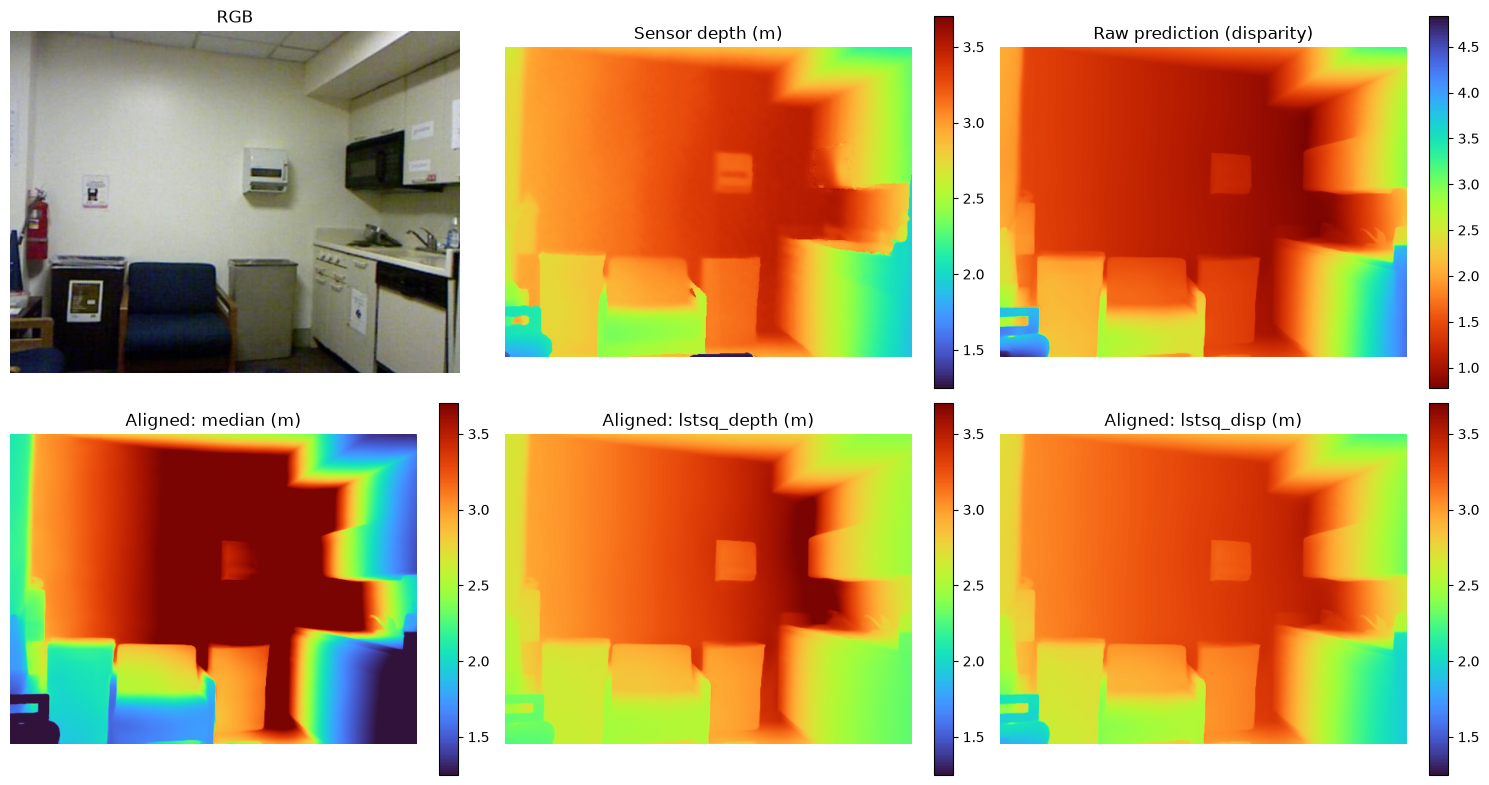

In [7]:
rgb = np.array(Image.open(DATASET_ROOT / sample["file_name"]).convert("RGB"))
vmin, vmax = sample_gt[v].min(), sample_gt[v].max()

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes[0, 0].imshow(rgb); axes[0, 0].set_title("RGB")
im = axes[0, 1].imshow(np.where(v, sample_gt, np.nan), cmap="turbo", vmin=vmin, vmax=vmax)
axes[0, 1].set_title("Sensor depth (m)"); fig.colorbar(im, ax=axes[0, 1], fraction=0.046)
im = axes[0, 2].imshow(sample_raw, cmap="turbo_r")
axes[0, 2].set_title("Raw prediction (disparity)"); fig.colorbar(im, ax=axes[0, 2], fraction=0.046)
for ax, method in zip(axes[1], METHODS):
    im = ax.imshow(np.where(sample_aligned[method] > 0, sample_aligned[method], np.nan),
                   cmap="turbo", vmin=vmin, vmax=vmax)
    ax.set_title(f"Aligned: {method} (m)"); fig.colorbar(im, ax=ax, fraction=0.046)
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.savefig(OUT_DIR / f"sample_{sample['id']}_alignment.png", dpi=150, bbox_inches="tight")
plt.show()

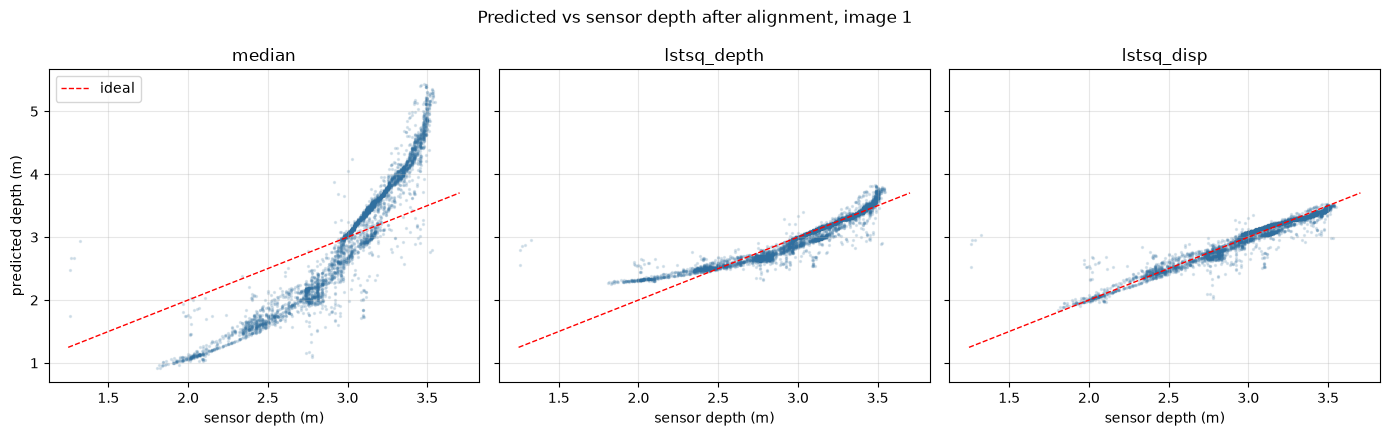

In [8]:
# scatter: predicted vs sensor depth (subsampled pixels), one panel per method
idx = np.random.default_rng(42).choice(int(v.sum()), size=min(4000, int(v.sum())), replace=False)
gt_pts = sample_gt[v][idx]

fig, axes = plt.subplots(1, 3, figsize=(14, 4.4), sharex=True, sharey=True)
for ax, method in zip(axes, METHODS):
    ax.scatter(gt_pts, sample_aligned[method][v][idx], s=2, alpha=0.15, color="#2f6f9f")
    ax.plot([vmin, vmax], [vmin, vmax], "r--", lw=1, label="ideal")
    ax.set_title(method); ax.set_xlabel("sensor depth (m)"); ax.grid(alpha=0.3)
axes[0].set_ylabel("predicted depth (m)"); axes[0].legend()
plt.suptitle(f"Predicted vs sensor depth after alignment, image {sample['id']}")
plt.tight_layout()
plt.savefig(OUT_DIR / f"sample_{sample['id']}_scatter.png", dpi=150, bbox_inches="tight")
plt.show()

---
## Global alignment fitted on validation

Per-image alignment needs the sensor map of *that* image at test time — it measures
the model's best possible geometry, but is not deployable. A single global transform
fitted once on the validation split is: it can be shipped with the model and applied
to a lone RGB frame.

The global parameters are the **median of per-image fits** over a validation subset —
more robust than pooling all pixels, which would let large images and near-field
surfaces dominate. The subset is **stratified by sensor** (50 random images per
sensor, seed 42): the first validation ids are all NYU/kv1 frames, and a fit on
them alone would silently tune the constants to one camera. Both variants are evaluated below; the gap between them is the
price of not knowing the scene scale.

In [9]:
rng = np.random.default_rng(42)
val_subset = []
for sensor in sorted({im["sensor"] for im in val_images}):
    pool = [im for im in val_images if im["sensor"] == sensor]
    pick = rng.choice(len(pool), size=min(N_FIT_PER_SENSOR, len(pool)), replace=False)
    val_subset += [pool[i] for i in sorted(pick)]
print("Global-fit subset:", len(val_subset), "validation images —",
      {s: sum(im["sensor"] == s for im in val_subset) for s in sorted({im["sensor"] for im in val_subset})})

fit_rows = []
t0 = time.time()
for n, info in enumerate(val_subset, 1):
    gt, raw = load_gt(info), predict_raw(info)
    if valid_mask(gt).sum() < 1000:
        continue
    fit_rows.append({"sensor": info["sensor"],
                     **{f"{m}_{k}": p for m in METHODS
                        for k, p in zip(("p1", "p2"), fit_alignment(raw, gt, m))}})
    if n % 25 == 0 or n == len(val_subset):
        print(f"  fitted on {n}/{len(val_subset)} val images "
              f"({n / (time.time() - t0):.2f} img/s)", end="\r")
print()

fit_df = pd.DataFrame(fit_rows)
GLOBAL_PARAMS = {m: (float(fit_df[f"{m}_p1"].median()), float(fit_df[f"{m}_p2"].median()))
                 for m in METHODS}
print(f"Global alignment from {len(fit_df)} validation images:")
for m, (p1, p2) in GLOBAL_PARAMS.items():
    spread = fit_df[f"{m}_p1"].quantile([0.25, 0.75]).values
    print(f"  {m:12s} p1={p1:9.4f}  p2={p2:8.4f}   (p1 IQR: {spread[0]:.3f}–{spread[1]:.3f})")

Global-fit subset: 200 validation images — {'kv1': 50, 'kv2': 50, 'realsense': 50, 'xtion': 50}


  fitted on 200/200 val images (6.94 img/s)
Global alignment from 200 validation images:
  median       p1=   5.2741  p2=  0.0000   (p1 IQR: 4.433–6.331)
  lstsq_depth  p1=   0.8486  p2=  1.6820   (p1 IQR: 0.000–1.438)
  lstsq_disp   p1=   0.0894  p2=  0.2743   (p1 IQR: 0.069–0.112)


---
## Test-set evaluation

Every method is evaluated per-image and globally on the same pixels. The aligned
depth of the best method is stored as `.npy` (float16) for the first `N_SAVE`
images, in two variants — per-image (oracle) and global (deployable) — the
inputs for the monocular point clouds in chapter 3.

In [10]:
eval_subset = test_images if N_EVAL is None else test_images[:N_EVAL]
save_ids = {im["id"] for im in eval_subset[:N_SAVE]}
SAVE_METHOD = "lstsq_disp"     # per-image maps stored for the 3D stage

rows = []
t0 = time.time()
for n, info in enumerate(eval_subset, 1):
    gt, raw = load_gt(info), predict_raw(info)
    if valid_mask(gt).sum() < 1000:
        continue
    base = {"image_id": info["id"], "sensor": info["sensor"],
            "scene_type": info["scene_type"], "median_gt_depth": float(np.median(gt[valid_mask(gt)]))}
    for method in METHODS:
        z_img = apply_alignment(raw, fit_alignment(raw, gt, method), method)
        rows.append({**base, "method": method, "alignment": "per_image",
                     **depth_metrics(z_img, gt)})
        z_glob = apply_alignment(raw, GLOBAL_PARAMS[method], method)
        rows.append({**base, "method": method, "alignment": "global",
                     **depth_metrics(z_glob, gt)})
        if method == SAVE_METHOD and info["id"] in save_ids:
            np.save(MAP_DIR / f"{info['id']}.npy", z_img.astype(np.float16))
            np.save(MAP_DIR_GLOBAL / f"{info['id']}.npy", z_glob.astype(np.float16))
    if n % 25 == 0 or n == len(eval_subset):
        print(f"  {n}/{len(eval_subset)} images ({n / (time.time() - t0):.2f} img/s, "
              f"ETA {(len(eval_subset) - n) / max(n / (time.time() - t0), 1e-6) / 60:.0f} min)",
              end="\r")
print()

depth_df = pd.DataFrame(rows)
depth_df.to_csv(OUT_DIR / "depth_metrics_per_image.csv", index=False)
print(f"Evaluated {depth_df.image_id.nunique()} images in {(time.time() - t0) / 60:.1f} min")
print(f"Saved {sum((MAP_DIR / f'{i}.npy').exists() for i in save_ids)} per-image + "
      f"{sum((MAP_DIR_GLOBAL / f'{i}.npy').exists() for i in save_ids)} global aligned maps ({SAVE_METHOD}) "
      f"-> {MAP_DIR}, {MAP_DIR_GLOBAL}")

  1287/1287 images (5.71 img/s, ETA 0 min)
Evaluated 1287 images in 3.8 min
Saved 1287 per-image + 1287 global aligned maps (lstsq_disp) -> outputs/depth_mono/maps, outputs/depth_mono/maps_global


In [11]:
# main comparison table: alignment method x alignment mode
COLS = ["abs_rel", "rmse", "rmse_log", "delta1", "delta2", "delta3"]
summary = (depth_df.groupby(["alignment", "method"])[COLS].mean()
           .reindex(pd.MultiIndex.from_product([["per_image", "global"], METHODS],
                                               names=["alignment", "method"])))
summary.to_csv(OUT_DIR / "depth_metrics_summary.csv")
print("Lower is better: abs_rel, rmse, rmse_log | higher is better: delta1-3\n")
summary.round(4)

Lower is better: abs_rel, rmse, rmse_log | higher is better: delta1-3



abs_rel    rmse  rmse_log  delta1  delta2  delta3
alignment method                                                        
per_image median        0.3972  1.4724    0.4048  0.5531  0.8025  0.9148
          lstsq_depth   0.2567  0.6813    0.2834  0.6554  0.8540  0.9399
          lstsq_disp    0.1274  0.4865    0.1832  0.8635  0.9411  0.9696
global    median        0.5112  1.6419    0.4796  0.3721  0.6806  0.8632
          lstsq_depth   0.3480  0.9431    0.3702  0.4886  0.7803  0.9196
          lstsq_disp    0.2744  0.8205    0.3163  0.5177  0.8282  0.9417

Best per-image method by AbsRel: lstsq_disp


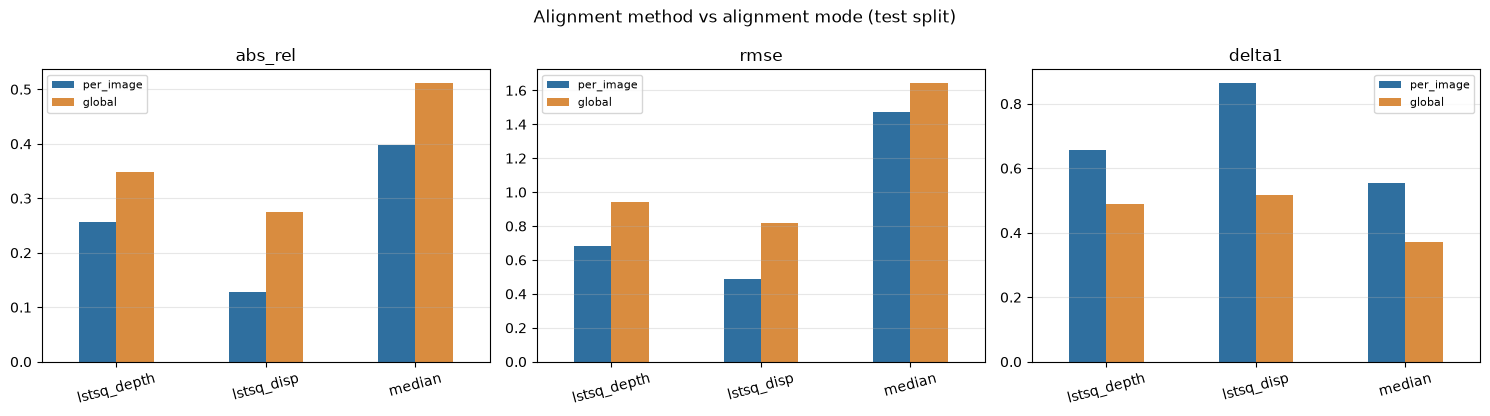

In [12]:
best = summary.loc["per_image", "abs_rel"].idxmin()
print(f"Best per-image method by AbsRel: {best}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, metric in zip(axes, ["abs_rel", "rmse", "delta1"]):
    pivot = summary[metric].unstack("alignment")[["per_image", "global"]]
    pivot.plot.bar(ax=ax, color=["#2f6f9f", "#d98c3f"], rot=15)
    ax.set_title(metric); ax.set_xlabel(""); ax.grid(axis="y", alpha=0.3)
    ax.legend(title="", fontsize=8)
plt.suptitle("Alignment method vs alignment mode (test split)")
plt.tight_layout()
plt.savefig(OUT_DIR / "alignment_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

---
## Error breakdown

Where the monocular model is weakest — the material for the discussion in 3.4.

In [13]:
sub = depth_df[(depth_df.method == best) & (depth_df.alignment == "per_image")].copy()

by_sensor = sub.groupby("sensor")[COLS + ["image_id"]].agg(
    {**{c: "mean" for c in COLS}, "image_id": "count"}).rename(columns={"image_id": "n_images"})
print(f"By sensor ({best}, per-image alignment):")
display(by_sensor.round(4))

sub["distance_bin"] = pd.cut(sub.median_gt_depth, [0, 1.5, 2.5, 3.5, 5.0, MAX_DEPTH],
                             labels=["<1.5 m", "1.5–2.5", "2.5–3.5", "3.5–5", ">5 m"])
by_distance = sub.groupby("distance_bin", observed=True)[COLS + ["image_id"]].agg(
    {**{c: "mean" for c in COLS}, "image_id": "count"}).rename(columns={"image_id": "n_images"})
print("\nBy scene distance (median sensor depth of the frame):")
display(by_distance.round(4))

by_sensor.to_csv(OUT_DIR / "depth_metrics_by_sensor.csv")
by_distance.to_csv(OUT_DIR / "depth_metrics_by_distance.csv")

By sensor (lstsq_disp, per-image alignment):


,abs_rel,rmse,rmse_log,delta1,delta2,delta3,n_images
sensor,,,,,,,
kv1,0.0938,0.3977,0.1439,0.9179,0.9705,0.9862,239
kv2,0.1572,0.6474,0.2259,0.8194,0.9139,0.9541,509
realsense,0.1997,0.5268,0.2677,0.7384,0.8912,0.9390,153
xtion,0.0802,0.3132,0.1179,0.9377,0.9786,0.9917,386



By scene distance (median sensor depth of the frame):


,abs_rel,rmse,rmse_log,delta1,delta2,delta3,n_images
distance_bin,,,,,,,
<1.5 m,0.1021,0.3023,0.1586,0.8909,0.9554,0.9817,100
1.5–2.5,0.1306,0.4667,0.1871,0.8580,0.9387,0.9677,822
2.5–3.5,0.1314,0.5931,0.1868,0.8601,0.9373,0.9679,308
3.5–5,0.1041,0.5127,0.1509,0.9127,0.9719,0.9848,56
>5 m,0.1053,0.8614,0.1632,0.9576,0.9801,0.9858,1


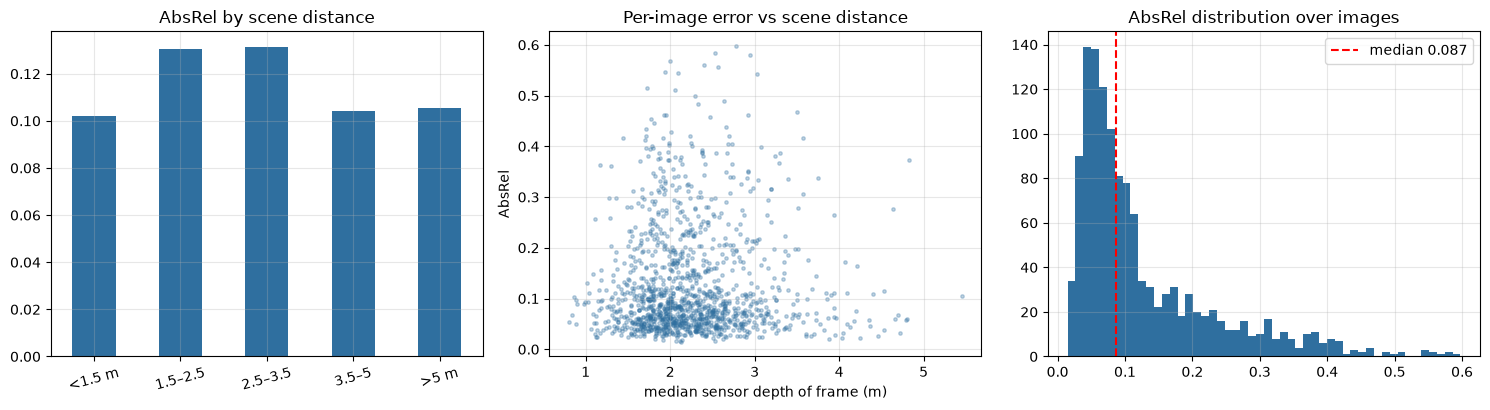

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
by_distance["abs_rel"].plot.bar(ax=axes[0], color="#2f6f9f", rot=15)
axes[0].set_title("AbsRel by scene distance"); axes[0].set_xlabel("")
axes[1].scatter(sub.median_gt_depth, sub.abs_rel, s=6, alpha=0.3, color="#2f6f9f")
axes[1].set_xlabel("median sensor depth of frame (m)"); axes[1].set_ylabel("AbsRel")
axes[1].set_title("Per-image error vs scene distance")
axes[2].hist(sub.abs_rel, bins=50, color="#2f6f9f")
axes[2].axvline(sub.abs_rel.median(), color="r", ls="--", label=f"median {sub.abs_rel.median():.3f}")
axes[2].set_title("AbsRel distribution over images"); axes[2].legend()
for ax in axes: ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(OUT_DIR / "error_breakdown.png", dpi=150, bbox_inches="tight")
plt.show()

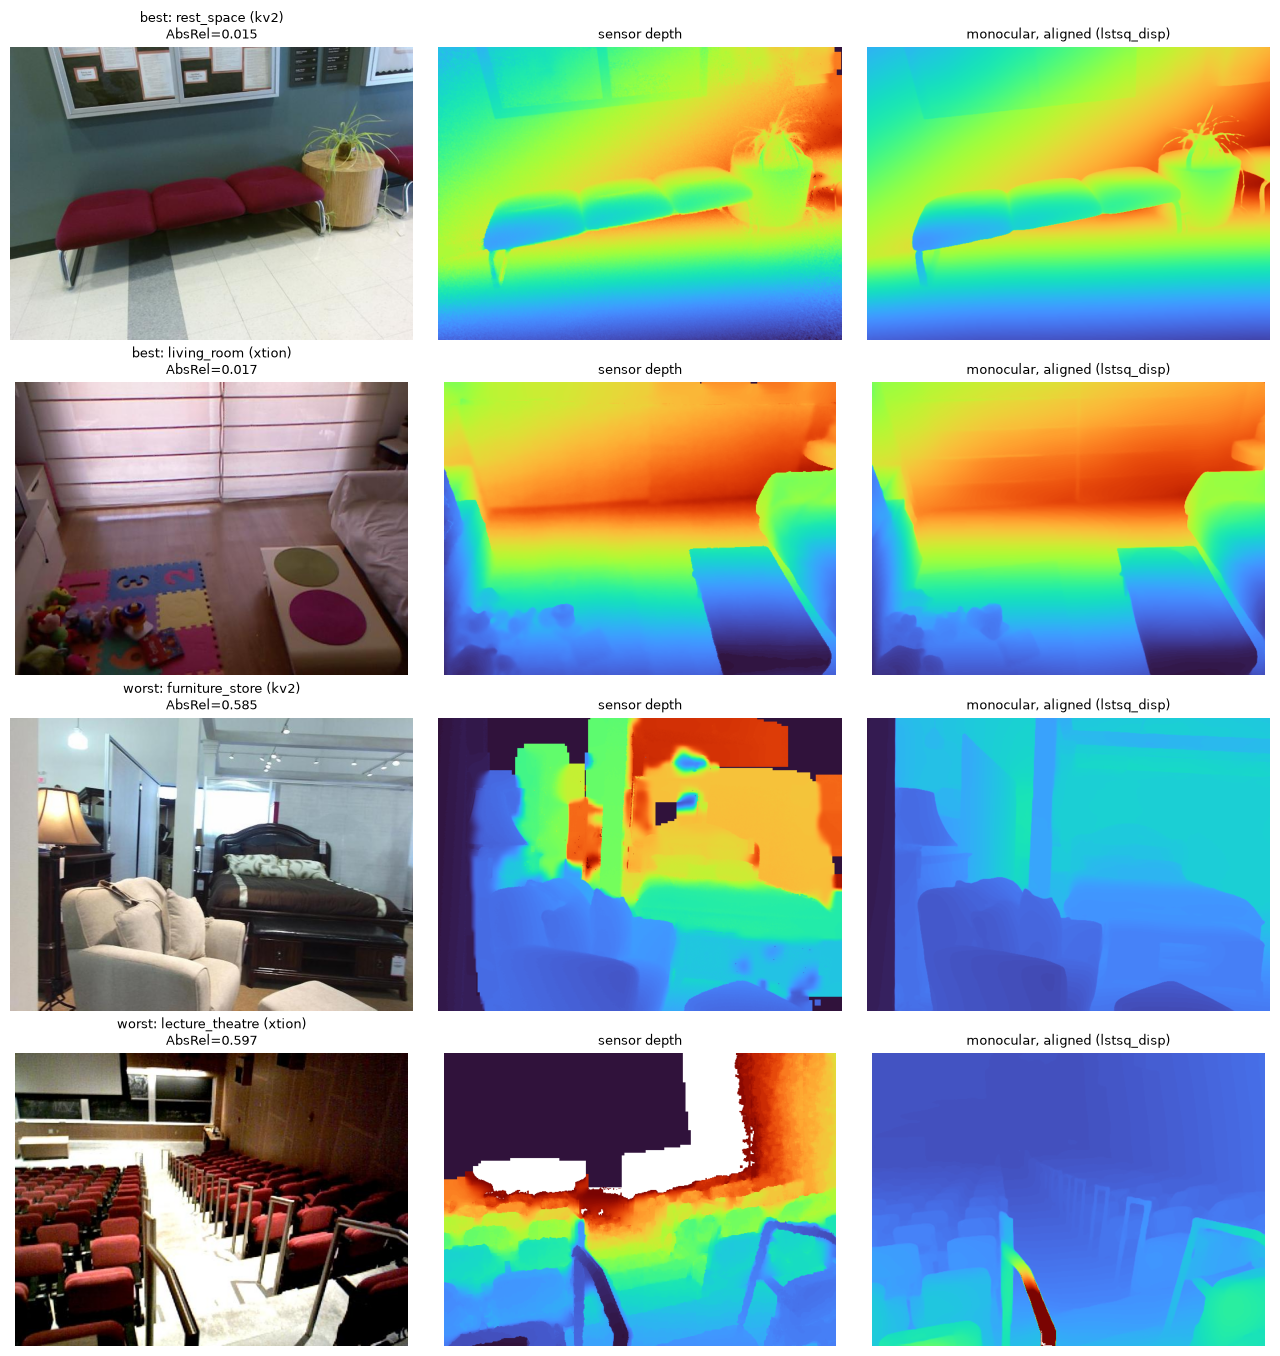

In [15]:
# qualitative extremes: the two easiest and the two hardest frames
ranked = sub.sort_values("abs_rel")
picks = [("best", r) for _, r in ranked.head(2).iterrows()] + \
        [("worst", r) for _, r in ranked.tail(2).iterrows()]
by_id = {im["id"]: im for im in test_images}

fig, axes = plt.subplots(len(picks), 3, figsize=(13, 3.4 * len(picks)))
for row, (label, rec) in zip(axes, picks):
    info = by_id[rec.image_id]
    gt, raw = load_gt(info), predict_raw(info)
    z = apply_alignment(raw, fit_alignment(raw, gt, best), best)
    vm = valid_mask(gt)
    lo, hi = gt[vm].min(), gt[vm].max()
    row[0].imshow(np.array(Image.open(DATASET_ROOT / info["file_name"]).convert("RGB")))
    row[0].set_title(f"{label}: {info['scene_type']} ({info['sensor']})\nAbsRel={rec.abs_rel:.3f}",
                     fontsize=9)
    row[1].imshow(np.where(vm, gt, np.nan), cmap="turbo", vmin=lo, vmax=hi)
    row[1].set_title("sensor depth", fontsize=9)
    row[2].imshow(np.where(z > 0, z, np.nan), cmap="turbo", vmin=lo, vmax=hi)
    row[2].set_title(f"monocular, aligned ({best})", fontsize=9)
    for ax in row: ax.axis("off")
plt.tight_layout()
plt.savefig(OUT_DIR / "qualitative_best_worst.png", dpi=150, bbox_inches="tight")
plt.show()

---
## Inference timing

Measured the same way as the segmentation models (batch 1, warmup + timed runs), so
the depth stage can be added to the end-to-end budget of the pipeline. These are MPS
numbers — the comparison table in 2.3 uses T4 timings and these must not be mixed
into it.

In [16]:
timing_img = Image.open(DATASET_ROOT / test_images[0]["file_name"]).convert("RGB")
timing_inputs = processor(images=timing_img, return_tensors="pt").to(DEVICE)

for _ in range(10):                                   # warmup
    with torch.no_grad():
        model(**timing_inputs)
if DEVICE == "mps":
    torch.mps.synchronize()

times = []
for _ in range(50):
    t = time.perf_counter()
    with torch.no_grad():
        model(**timing_inputs)
    if DEVICE == "mps":
        torch.mps.synchronize()
    times.append((time.perf_counter() - t) * 1000)

times = np.array(times)
print(f"{MODEL_ID} on {DEVICE}, batch 1, 10 warmup + 50 runs:")
print(f"  mean {times.mean():.1f} ms | median {np.median(times):.1f} ms | "
      f"std {times.std():.1f} ms | {1000 / times.mean():.1f} img/s")

depth-anything/Depth-Anything-V2-Small-hf on mps, batch 1, 10 warmup + 50 runs:
  mean 38.0 ms | median 37.9 ms | std 0.5 ms | 26.3 img/s


---
## Metric indoor models: is alignment still needed?

Depth Anything V2 also ships *metric* variants — the same encoder fine-tuned on
the synthetic indoor dataset Hypersim with a head that regresses metres directly
(`max_depth = 20`). If that output were accurate as-is, none of the alignment
machinery above would be needed in the application. Three questions on the very
same test protocol (same images, same valid pixels, same metrics):

1. what the raw output actually is — depth or disparity (checked, not assumed);
2. how accurate it is **without any alignment** — the fully sensor-free case;
3. whether a **single global scale factor** (one constant fitted on the same
   validation images, exactly as deployable as the global affine of the relative
   model) removes the residual bias — and how the sensor-free configurations
   compare with the relative model + global `lstsq_disp`;
4. whether the bias is a **field-of-view effect**: a metric model implicitly
   assumes the focal length of its training camera, so with a real focal length
   `fx` the prediction should be off by `s = (fx / W) / F₀` — one constant `F₀`
   shared by all cameras (`focal` method; needs the intrinsics, which the demo has).

Per-image scale / affine fits are reported as oracles for symmetry with the
relative model; `affine` is a least-squares line in depth space (`z = a·d + b`).


In [17]:
METRIC_MODELS = {
    "metric_small": "depth-anything/Depth-Anything-V2-Metric-Indoor-Small-hf",
    "metric_base":  "depth-anything/Depth-Anything-V2-Metric-Indoor-Base-hf",
}
METRIC_METHODS = ["none", "scale", "focal", "affine"]   # z = d | s*d | (fx/W)/F0 * d | a*d + b
SAVE_METRIC_METHODS = ["scale", "focal"]                 # test maps stored for notebook 08
METRIC_MAP_DIRS = {(name, m): OUT_DIR / f"maps_{name}_{m}"
                   for name in METRIC_MODELS for m in SAVE_METRIC_METHODS}


def fx_per_width(img_info: dict) -> float:
    return float(img_info["fx"]) / float(img_info["width"])


def load_depth_model(model_id: str):
    proc = AutoImageProcessor.from_pretrained(model_id)
    mdl = AutoModelForDepthEstimation.from_pretrained(model_id).to(DEVICE).eval()
    return proc, mdl


def predict_with(proc, mdl, img_info: dict) -> np.ndarray:
    """`predict_raw` for an arbitrary (processor, model) pair."""
    image = Image.open(DATASET_ROOT / img_info["file_name"]).convert("RGB")
    inputs = proc(images=image, return_tensors="pt").to(DEVICE)
    with torch.no_grad():
        outputs = mdl(**inputs)
    post = proc.post_process_depth_estimation(
        outputs, target_sizes=[(img_info["height"], img_info["width"])])
    depth = post[0]["predicted_depth"].cpu().numpy().astype(np.float32)
    del inputs, outputs, post
    if DEVICE == "mps":
        torch.mps.empty_cache()
    return depth


def fit_metric_alignment(d: np.ndarray, gt: np.ndarray, method: str) -> tuple[float, float]:
    """(a, b) of z = a * d + b fitted on valid pixels; 'none' is the identity."""
    v = valid_mask(gt) & (d > 0)
    if method == "none":
        return 1.0, 0.0
    if method in ("scale", "focal"):
        return float(np.median(gt[v]) / max(np.median(d[v]), EPS)), 0.0
    if method == "affine":
        a, b = np.polyfit(d[v], gt[v], 1)
        return float(a), float(b)
    raise ValueError(method)


def apply_metric_alignment(d: np.ndarray, params: tuple[float, float]) -> np.ndarray:
    a, b = params
    z = np.where(np.isfinite(d), a * d + b, 0.0)
    return np.clip(z, 0.0, MAX_DEPTH).astype(np.float32)


def time_model(proc, mdl, n_warmup: int = 10, n_runs: int = 50) -> dict:
    """Batch-1 latency, same protocol as the timing cell of the relative model."""
    img = Image.open(DATASET_ROOT / test_images[0]["file_name"]).convert("RGB")
    inputs = proc(images=img, return_tensors="pt").to(DEVICE)
    for _ in range(n_warmup):
        with torch.no_grad():
            mdl(**inputs)
    if DEVICE == "mps":
        torch.mps.synchronize()
    times = []
    for _ in range(n_runs):
        t = time.perf_counter()
        with torch.no_grad():
            mdl(**inputs)
        if DEVICE == "mps":
            torch.mps.synchronize()
        times.append((time.perf_counter() - t) * 1000)
    times = np.array(times)
    return {"mean_ms": float(times.mean()), "median_ms": float(np.median(times)),
            "std_ms": float(times.std()), "img_per_s": float(1000 / times.mean())}


In [18]:
metric_rows, metric_fits, metric_timing = [], [], {}
METRIC_GLOBAL_PARAMS, metric_sample = {}, {}

for name, model_id in METRIC_MODELS.items():
    proc, mdl = load_depth_model(model_id)
    n_params = sum(p.numel() for p in mdl.parameters()) / 1e6
    print(f"\n{name}: {model_id} ({n_params:.1f}M parameters, "
          f"max_depth = {mdl.config.max_depth} m)")

    # 1. output convention — the same correlation test as for the relative model
    corr_d, corr_i = [], []
    for info in test_images[:20]:
        gt, d = load_gt(info), predict_with(proc, mdl, info)
        v = valid_mask(gt)
        if v.sum() < 1000:
            continue
        corr_d.append(np.corrcoef(d[v], gt[v])[0, 1])
        corr_i.append(np.corrcoef(d[v], 1.0 / gt[v])[0, 1])
    print(f"  corr(raw, depth) = {np.mean(corr_d):+.3f}, corr(raw, 1/depth) = "
          f"{np.mean(corr_i):+.3f} -> raw output is "
          f"{'DEPTH' if np.mean(corr_d) > np.mean(corr_i) else 'DISPARITY'}")
    assert np.mean(corr_d) > np.mean(corr_i), "metric model expected to output depth"

    # 2. global parameters on the same validation images as the relative model
    fits = []
    for info in val_subset:
        gt, d = load_gt(info), predict_with(proc, mdl, info)
        if valid_mask(gt).sum() < 1000:
            continue
        fits.append({"model": name, "sensor": info["sensor"],
                     "fx_per_width": fx_per_width(info),
                     **{f"{m}_{k}": p for m in ("scale", "affine")
                        for k, p in zip(("p1", "p2"), fit_metric_alignment(d, gt, m))}})
    fits = pd.DataFrame(fits)
    metric_fits.append(fits)
    # F0 = the focal length (per unit image width) the metric model implicitly assumes
    F0 = float((fits.fx_per_width / fits.scale_p1).median())
    glob = {"none": (1.0, 0.0),
            "scale": (float(fits.scale_p1.median()), 0.0),
            "affine": (float(fits.affine_p1.median()), float(fits.affine_p2.median())),
            "F0": F0}
    METRIC_GLOBAL_PARAMS[name] = glob
    q = fits.scale_p1.quantile([0.25, 0.75]).values
    print(f"  global scale s = {glob['scale'][0]:.4f} (IQR {q[0]:.3f}-{q[1]:.3f}), "
          f"global affine a = {glob['affine'][0]:.4f}, b = {glob['affine'][1]:+.4f}, "
          f"focal F0 = {F0:.4f} (s = fx/W / F0) from {len(fits)} validation images")

    # 3. test split: deployable variants (none / global) + per-image oracles
    for m in SAVE_METRIC_METHODS:
        METRIC_MAP_DIRS[(name, m)].mkdir(parents=True, exist_ok=True)
    t0 = time.time()
    for n, info in enumerate(eval_subset, 1):
        gt, d = load_gt(info), predict_with(proc, mdl, info)
        if info["id"] == sample["id"]:
            metric_sample[name] = d
        if valid_mask(gt).sum() < 1000:
            continue
        base = {"model": name, "image_id": info["id"], "sensor": info["sensor"],
                "scene_type": info["scene_type"],
                "median_gt_depth": float(np.median(gt[valid_mask(gt)])),
                "median_ratio_raw": float(np.median(d[valid_mask(gt)] / gt[valid_mask(gt)]))}
        for method in METRIC_METHODS:
            params = (fx_per_width(info) / glob["F0"], 0.0) if method == "focal" else glob[method]
            z_glob = apply_metric_alignment(d, params)
            metric_rows.append({**base, "method": method,
                                "alignment": "none" if method == "none" else "global",
                                **depth_metrics(z_glob, gt)})
            if method in ("scale", "affine"):
                z_img = apply_metric_alignment(d, fit_metric_alignment(d, gt, method))
                metric_rows.append({**base, "method": method, "alignment": "per_image",
                                    **depth_metrics(z_img, gt)})
            if method in SAVE_METRIC_METHODS and info["id"] in save_ids:
                np.save(METRIC_MAP_DIRS[(name, method)] / f"{info['id']}.npy",
                        z_glob.astype(np.float16))
        if n % 25 == 0 or n == len(eval_subset):
            print(f"  {n}/{len(eval_subset)} images ({n / (time.time() - t0):.2f} img/s)", end="\r")
    print("\n  saved test maps:", {m: sum((METRIC_MAP_DIRS[(name, m)] / f"{i}.npy").exists()
                                       for i in save_ids)
                                for m in SAVE_METRIC_METHODS})

    metric_timing[name] = time_model(proc, mdl)
    print(f"  timing ({DEVICE}, batch 1): mean {metric_timing[name]['mean_ms']:.1f} ms, "
          f"{metric_timing[name]['img_per_s']:.1f} img/s")
    del mdl, proc
    if DEVICE == "mps":
        torch.mps.empty_cache()

metric_df = pd.DataFrame(metric_rows)
metric_df.to_csv(OUT_DIR / "depth_metrics_metric_per_image.csv", index=False)
metric_fits = pd.concat(metric_fits, ignore_index=True)
print(f"\nEvaluated {metric_df.image_id.nunique()} test images x {len(METRIC_MODELS)} metric models")


Loading weights:   0%|          | 0/287 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 287/287 [00:00<00:00, 8381.60it/s]


metric_small: depth-anything/Depth-Anything-V2-Metric-Indoor-Small-hf (24.8M parameters, max_depth = 20 m)


  corr(raw, depth) = +0.758, corr(raw, 1/depth) = -0.691 -> raw output is DEPTH


/var/folders/_6/6l9ldxk5661c4mwnv11kfsh40000gn/T/ipykernel_4586/1950515128.py:44: RankWarning: Polyfit may be poorly conditioned
  a, b = np.polyfit(d[v], gt[v], 1)


  global scale s = 0.8573 (IQR 0.763-0.964), global affine a = 0.7941, b = +0.1857, focal F0 = 1.0278 (s = fx/W / F0) from 200 validation images


... (12 outputs left out)

/var/folders/_6/6l9ldxk5661c4mwnv11kfsh40000gn/T/ipykernel_4586/1950515128.py:44: RankWarning: Polyfit may be poorly conditioned
  a, b = np.polyfit(d[v], gt[v], 1)


/var/folders/_6/6l9ldxk5661c4mwnv11kfsh40000gn/T/ipykernel_4586/1950515128.py:44: RankWarning: Polyfit may be poorly conditioned
  a, b = np.polyfit(d[v], gt[v], 1)


  1287/1287 images (5.00 img/s)
  saved test maps: {'scale': 1287, 'focal': 1287}


  timing (mps, batch 1): mean 91.3 ms, 11.0 img/s

Evaluated 1287 test images x 2 metric models


### All depth configurations on one table

`relative_small` rows are the relative model above; `alignment = none` is the
raw metric output, `global` uses one constant (`scale`) or two (`affine`)
fitted on validation, `per_image` is the oracle. The deployable rows — the
ones an RGB-only application can actually use — are marked in the plot below.


In [19]:
ORDER = [("relative_small", "per_image", "lstsq_disp"),
         ("relative_small", "global", "lstsq_disp")]
for name in METRIC_MODELS:
    ORDER += [(name, "none", "none"), (name, "global", "scale"), (name, "global", "focal"),
              (name, "global", "affine"),
              (name, "per_image", "scale"), (name, "per_image", "affine")]

rel_summary = summary.copy()
rel_summary.index = pd.MultiIndex.from_tuples(
    [("relative_small", a, m) for a, m in rel_summary.index], names=["model", "alignment", "method"])
metric_summary = metric_df.groupby(["model", "alignment", "method"])[COLS].mean()
summary_all = pd.concat([rel_summary, metric_summary]).reindex(pd.MultiIndex.from_tuples(
    ORDER, names=["model", "alignment", "method"]))
summary_all.to_csv(OUT_DIR / "depth_metrics_summary_all.csv")
print("Lower is better: abs_rel, rmse, rmse_log | higher is better: delta1-3\n")
summary_all.round(4)


Lower is better: abs_rel, rmse, rmse_log | higher is better: delta1-3



abs_rel    rmse  rmse_log  delta1  \
model          alignment method                                          
relative_small per_image lstsq_disp   0.1274  0.4865    0.1832  0.8635   
               global    lstsq_disp   0.2744  0.8205    0.3163  0.5177   
metric_small   none      none         0.3387  0.8762    0.3225  0.5640   
               global    scale        0.2332  0.6682    0.2599  0.7656   
                         focal        0.2585  0.7131    0.2805  0.6754   
                         affine       0.2335  0.6526    0.2583  0.7678   
               per_image scale        0.1736  0.5620    0.2162  0.8638   
                         affine       0.1496  0.4665    0.1936  0.8639   
metric_base    none      none         0.3276  0.8751    0.3098  0.6110   
               global    scale        0.2211  0.6628    0.2456  0.8401   
                         focal        0.2344  0.6817    0.2579  0.7759   
                         affine       0.2138  0.6335    0.2409  0.8397   
               per_image scale        0.1721  0.5717    0.2131  0.8832   
                         affine       0.1445  0.4562    0.1881  0.8692   

                                     delta2  delta3  
model          alignment method                      
relative_small per_image lstsq_disp  0.9411  0.9696  
               global    lstsq_disp  0.8282  0.9417  
metric_small   none      none        0.9027  0.9590  
               global    scale       0.9336  0.9651  
                         focal       0.9171  0.9647  
                         affine      0.9340  0.9664  
               per_image scale       0.9486  0.9698  
                         affine      0.9501  0.9731  
metric_base    none      none        0.9293  0.9621  
               global    scale       0.9477  0.9664  
                         focal       0.9410  0.9666  
                         affine      0.9492  0.9675  
               per_image scale       0.9505  0.9688  
                         affine      0.9502  0.9727

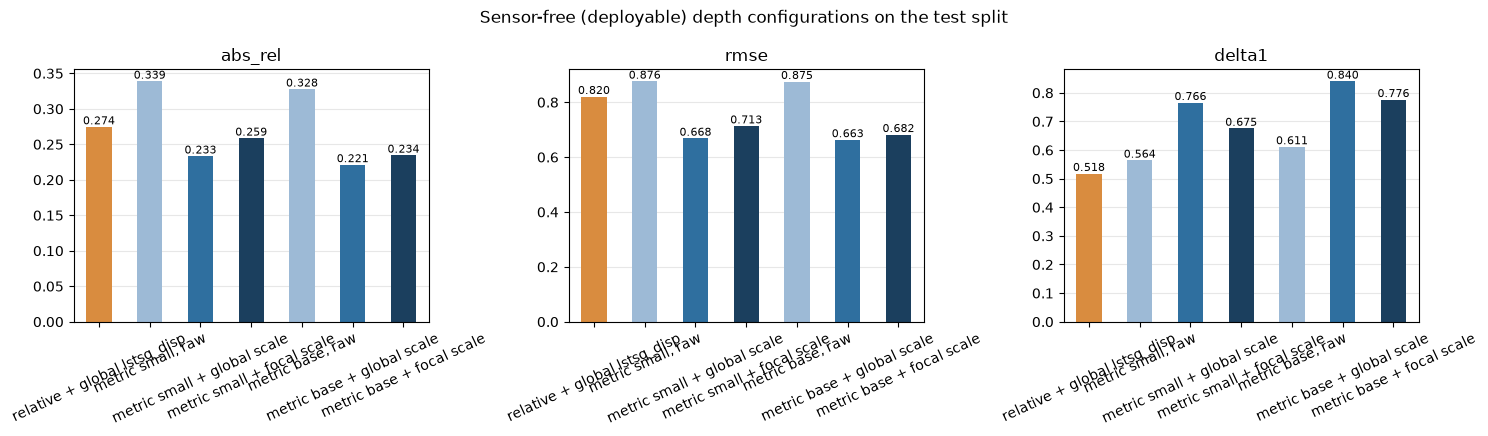

,abs_rel,rmse,rmse_log,delta1,delta2,delta3
relative + global lstsq_disp,0.2744,0.8205,0.3163,0.5177,0.8282,0.9417
"metric small, raw",0.3387,0.8762,0.3225,0.5640,0.9027,0.9590
metric small + global scale,0.2332,0.6682,0.2599,0.7656,0.9336,0.9651
metric small + focal scale,0.2585,0.7131,0.2805,0.6754,0.9171,0.9647
"metric base, raw",0.3276,0.8751,0.3098,0.6110,0.9293,0.9621
metric base + global scale,0.2211,0.6628,0.2456,0.8401,0.9477,0.9664
metric base + focal scale,0.2344,0.6817,0.2579,0.7759,0.9410,0.9666


In [20]:
DEPLOYABLE = [("relative_small", "global", "lstsq_disp", "relative + global lstsq_disp")]
for name in METRIC_MODELS:
    tag = name.replace("metric_", "metric ")
    DEPLOYABLE += [(name, "none", "none", f"{tag}, raw"),
                   (name, "global", "scale", f"{tag} + global scale"),
                   (name, "global", "focal", f"{tag} + focal scale")]
dep = summary_all.loc[[d[:3] for d in DEPLOYABLE]]
dep.index = [d[3] for d in DEPLOYABLE]
dep.to_csv(OUT_DIR / "depth_metrics_deployable.csv")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
colors = ["#d98c3f"] + ["#9dbad6", "#2f6f9f", "#1b3f5e"] * len(METRIC_MODELS)
for ax, metric in zip(axes, ["abs_rel", "rmse", "delta1"]):
    dep[metric].plot.bar(ax=ax, color=colors, rot=25)
    ax.set_title(metric); ax.grid(axis="y", alpha=0.3); ax.set_axisbelow(True)
    for i, v in enumerate(dep[metric]):
        ax.text(i, v, f"{v:.3f}", ha="center", va="bottom", fontsize=8)
plt.suptitle("Sensor-free (deployable) depth configurations on the test split")
plt.tight_layout()
plt.savefig(OUT_DIR / "deployable_comparison.png", dpi=150, bbox_inches="tight")
plt.show()
dep.round(4)


### Where does the metric bias come from?

A metric model must implicitly assume a camera field of view: the same object
at the same pixel size is farther away for a narrower lens. Hypersim renders
use one fixed camera, SUN RGB-D mixes four sensors with different focal
lengths — so if the raw error is a *per-sensor* scale bias that tracks
`fx / width`, the residual is a FOV mismatch rather than a failure of the model.
The table compares the per-sensor median of the fitted scale with the scale the
`focal` rule predicts from that sensor's `fx / W` alone.


In [21]:
val_fov = (pd.DataFrame(val_images).assign(fx_per_width=lambda t: t.fx / t.width)
           .groupby("sensor").fx_per_width.median())
by_sensor_scale = metric_fits.groupby(["sensor", "model"]).scale_p1.median().unstack("model")
focal_pred = pd.DataFrame({f"focal_pred_{name}": val_fov / METRIC_GLOBAL_PARAMS[name]["F0"]
                           for name in METRIC_MODELS})
raw_by_sensor = (metric_df[metric_df.alignment == "none"]
                 .groupby(["sensor", "model"]).abs_rel.mean().unstack("model")
                 .rename(columns=lambda c: f"abs_rel_raw_{c}"))
scaled_by_sensor = pd.concat([
    metric_df[(metric_df.alignment == "global") & (metric_df.method == m)]
    .groupby(["sensor", "model"]).abs_rel.mean().unstack("model")
    .rename(columns=lambda c, m=m: f"abs_rel_{m}_{c}") for m in ("scale", "focal")], axis=1)
rel_by_sensor = (depth_df[(depth_df.alignment == "global") & (depth_df.method == "lstsq_disp")]
                 .groupby("sensor").abs_rel.mean().rename("abs_rel_relative_global"))
sensor_table = pd.concat([val_fov.rename("fx_per_width"),
                          by_sensor_scale.rename(columns=lambda c: f"fitted_scale_{c}"),
                          focal_pred,
                          raw_by_sensor, scaled_by_sensor, rel_by_sensor], axis=1)
sensor_table.to_csv(OUT_DIR / "metric_scale_by_sensor.csv")
print("Median per-image scale factor s (validation) and test AbsRel by sensor:")
sensor_table.round(3)


Median per-image scale factor s (validation) and test AbsRel by sensor:


,fx_per_width,fitted_scale_metric_base,fitted_scale_metric_small,focal_pred_metric_small,focal_pred_metric_base,abs_rel_raw_metric_base,abs_rel_raw_metric_small,abs_rel_scale_metric_base,abs_rel_scale_metric_small,abs_rel_focal_metric_base,abs_rel_focal_metric_small,abs_rel_relative_global
sensor,,,,,,,,,,,,
kv1,0.925,0.868,0.845,0.900,0.891,0.243,0.299,0.156,0.194,0.165,0.217,0.306
kv2,0.725,0.784,0.798,0.706,0.698,0.421,0.388,0.285,0.270,0.286,0.283,0.278
realsense,1.019,0.973,1.014,0.991,0.981,0.312,0.317,0.304,0.325,0.303,0.315,0.313
xtion,0.965,0.851,0.829,0.939,0.929,0.263,0.308,0.144,0.172,0.182,0.230,0.235


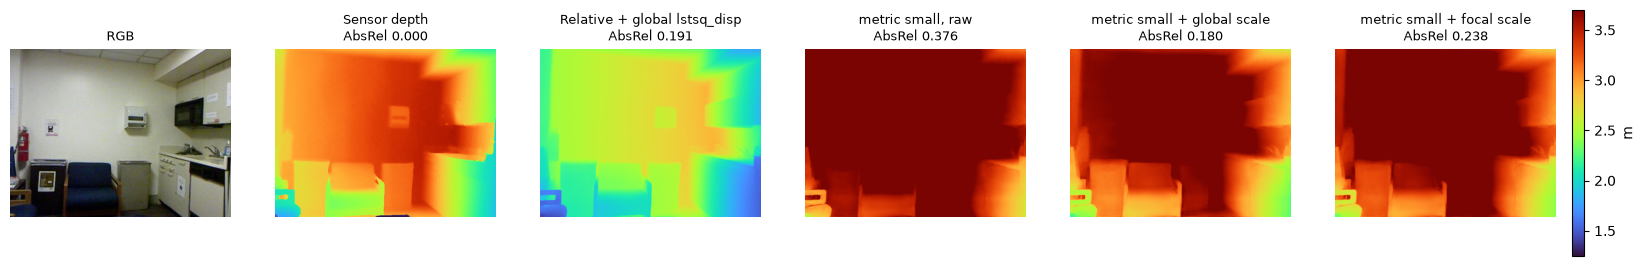

In [22]:
# the walkthrough scene: sensor vs the deployable configurations
v_s = valid_mask(sample_gt)
z_rel_glob = apply_alignment(sample_raw, GLOBAL_PARAMS["lstsq_disp"], "lstsq_disp")
panels = [("Sensor depth", np.where(v_s, sample_gt, np.nan)),
          ("Relative + global lstsq_disp", np.where(z_rel_glob > 0, z_rel_glob, np.nan))]
for name in ["metric_small"]:
    d = metric_sample[name]
    g = METRIC_GLOBAL_PARAMS[name]
    z_scaled = apply_metric_alignment(d, g["scale"])
    z_focal = apply_metric_alignment(d, (fx_per_width(sample) / g["F0"], 0.0))
    tag = name.replace("metric_", "metric ")
    panels += [(f"{tag}, raw", d), (f"{tag} + global scale", z_scaled),
               (f"{tag} + focal scale", z_focal)]

fig, axes = plt.subplots(1, len(panels) + 1, figsize=(3.4 * (len(panels) + 1), 3.2))
axes[0].imshow(rgb); axes[0].set_title("RGB", fontsize=9)
for ax, (title, z) in zip(axes[1:], panels):
    im = ax.imshow(np.where(z > 0, z, np.nan), cmap="turbo", vmin=vmin, vmax=vmax)
    err = np.nanmean(np.abs(z[v_s] - sample_gt[v_s]) / sample_gt[v_s])
    ax.set_title(f"{title}\nAbsRel {err:.3f}", fontsize=9)
for ax in axes:
    ax.axis("off")
fig.colorbar(im, ax=axes, fraction=0.012, pad=0.01, label="m")
plt.savefig(OUT_DIR / f"sample_{sample['id']}_metric.png", dpi=150, bbox_inches="tight")
plt.show()


In [23]:
timing_table = pd.DataFrame(metric_timing).T
timing_table.loc["relative_small"] = {"mean_ms": times.mean(), "median_ms": np.median(times),
                                      "std_ms": times.std(), "img_per_s": 1000 / times.mean()}
timing_table.to_csv(OUT_DIR / "depth_timing_mps.csv")
print(f"Batch-1 latency on {DEVICE} (10 warmup + 50 runs) — MPS numbers, not for the T4 table:")
timing_table.round(1)


Batch-1 latency on mps (10 warmup + 50 runs) — MPS numbers, not for the T4 table:


,mean_ms,median_ms,std_ms,img_per_s
metric_small,37.5,37.5,0.4,26.7
metric_base,91.3,91.1,0.6,11.0
relative_small,38.0,37.9,0.5,26.3


### Findings: metric models

- **The raw output is depth** (corr +0.76 / +0.77 with sensor depth, −0.69 / −0.71
  with its inverse, Small / Base) — no disparity conversion needed. But it is
  *not* accurate as-is: AbsRel 0.34 (Small) / 0.33 (Base), worse than the
  relative model with its global alignment (0.274). The error is a consistent
  **over-estimation of scale** (median predicted/sensor ratio ≈ 1.2 on the test
  split, column `median_ratio_raw` of `depth_metrics_metric_per_image.csv`).
- **One constant fixes most of it.** A single global scale factor fitted on
  200 validation images (s = 0.857 Small, 0.862 Base) gives **AbsRel 0.233 /
  δ₁ 0.77 (Small)** and **0.221 / 0.84 (Base)** — the best sensor-free
  configurations by a wide margin over the relative model + global
  `lstsq_disp` (0.274 / 0.52). A global affine (two constants) adds little
  (0.234 Small, 0.214 Base): the bias is essentially a pure scale, the shift
  term buys at most 0.007 AbsRel.
- **The FOV hypothesis holds only qualitatively.** The implied focal length is
  F₀ ≈ 1.03·W (Small; 1.04·W Base — a ~52° horizontal field of view). Per-sensor
  fitted scales (Small) follow the focal-length order of the cameras at the ends
  (kv2 0.80 < xtion 0.83 < kv1 0.85 < realsense 1.01 for fx/W = 0.73, 0.97,
  0.93, 1.02) but not proportionally — the focal rule over-corrects kv2 (0.71
  predicted vs 0.80 fitted) and xtion (0.94 vs 0.83), and on the test split
  `focal` is *worse* than the single constant (0.259 vs 0.233 Small; 0.234 vs
  0.221 Base). Part of the bias is therefore a camera effect, the rest reflects
  the depth statistics of each sensor's scenes; a single constant that needs no
  intrinsics is the better deployable choice.
- **Per sensor**, metric Small + global scale beats relative + global on kv1
  (0.194 vs 0.306) and xtion (0.172 vs 0.235), ties on kv2 (0.270 vs 0.278) and
  loses on realsense (0.325 vs 0.313) — the sensor with the longest focal
  length and the noisiest depth.
- **With a sensor in the loop the relative model is still the better
  geometry**: per-image oracles give 0.127 (relative, `lstsq_disp`) vs 0.150 /
  0.145 (metric Small / Base, affine). The metric models win only where it
  matters for the application — without the sensor.
- **Cost.** Metric Small runs at the same ~38 ms/image (MPS) as the relative
  Small model (37.5 vs 38.0 ms); Base is 2.4× slower (91 ms) for a further
  0.012 AbsRel.
- **Decision for the demo:** `Depth-Anything-V2-Metric-Indoor-Small` with the
  global scale s = 0.8573 (`app/pipeline.py`, backend `metric_scaled`). Its
  end-to-end 3D effect on predicted masks is measured in notebook 08.
- Protocol note: the global constants of *all* models are fitted on a
  **sensor-stratified** validation subset (50 per sensor). The first version of
  this notebook used the first 150 validation ids, which are all kv1 frames;
  on dataset v1, re-fitting improved the relative model's global row from
  AbsRel 0.310 to 0.279.


---
## Maps for the 20-class test split (notebook 08)

Notebook 08 also evaluates the 3D pipeline on all 20 min400 classes, over the
min400 test split. That split is the std10 test split plus 157 images whose
ground truth holds only the 10 extra classes (64 of the 97 test sinks and 166 of
the 487 test cabinets are on them), so their maps are written here: same models,
same alignment rules, same global parameters fitted on validation above. Only
maps are saved; every depth metric in this notebook stays on the 1287 std10 test
images.

In [24]:
# min400 test images outside the std10 test split; same skip rule as the test loops
std10_test_ids = {im["id"] for im in test_images}
with open(Path("outputs/splits_min400") / "instances_test.json") as f:
    extra_images = sorted((im for im in json.load(f)["images"] if im["id"] not in std10_test_ids),
                          key=lambda im: im["id"])

t0 = time.time()
extra_ids = set()
for info in extra_images:
    gt, raw = load_gt(info), predict_raw(info)
    if valid_mask(gt).sum() < 1000:
        continue
    z_img = apply_alignment(raw, fit_alignment(raw, gt, SAVE_METHOD), SAVE_METHOD)
    z_glob = apply_alignment(raw, GLOBAL_PARAMS[SAVE_METHOD], SAVE_METHOD)
    np.save(MAP_DIR / f"{info['id']}.npy", z_img.astype(np.float16))
    np.save(MAP_DIR_GLOBAL / f"{info['id']}.npy", z_glob.astype(np.float16))
    extra_ids.add(info["id"])

for name, model_id in METRIC_MODELS.items():
    proc, mdl = load_depth_model(model_id)
    glob = METRIC_GLOBAL_PARAMS[name]
    for info in extra_images:
        if info["id"] not in extra_ids:
            continue
        d = predict_with(proc, mdl, info)
        for method in SAVE_METRIC_METHODS:
            params = (fx_per_width(info) / glob["F0"], 0.0) if method == "focal" else glob[method]
            np.save(METRIC_MAP_DIRS[(name, method)] / f"{info['id']}.npy",
                    apply_metric_alignment(d, params).astype(np.float16))
    del mdl, proc
    if DEVICE == "mps":
        torch.mps.empty_cache()

map_dirs = [MAP_DIR, MAP_DIR_GLOBAL, *METRIC_MAP_DIRS.values()]
print(f"min400-only test images: {len(extra_images)}, maps saved for {len(extra_ids)} "
      f"({time.time() - t0:.0f} s)")
print("maps per directory (std10 + min400-only test images):",
      {p.name: len(list(p.glob("*.npy"))) for p in map_dirs})

Loading weights:   0%|          | 0/287 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 287/287 [00:00<00:00, 10698.61it/s]

Loading weights:   0%|          | 0/287 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 287/287 [00:00<00:00, 8767.92it/s]

min400-only test images: 157, maps saved for 157 (59 s)
maps per directory (std10 + min400-only test images): {'maps': 1444, 'maps_global': 1444, 'maps_metric_small_scale': 1444, 'maps_metric_small_focal': 1444, 'maps_metric_base_scale': 1444, 'maps_metric_base_focal': 1444}


---
## Notes and limitations

- **Relative, not metric.** The model outputs disparity up to an unknown affine
  transform; every number above exists only after alignment against sensor depth.
  Reporting monocular depth in metres without stating the alignment protocol would be
  meaningless — this is the central methodological caveat of chapter 3.
- **Per-image alignment is an oracle.** It uses the sensor map of the very frame
  being evaluated, so it upper-bounds the achievable geometry. The global variant is
  what a deployed application could actually use; the gap between the two rows is the
  honest cost of scale ambiguity and belongs in the text.
- **Sensor depth is not perfect ground truth.** `depth_bfx` is inpainted and still
  fails on glossy, transparent and distant surfaces. Errors there are shared between
  the two maps, so metrics are computed only on valid sensor pixels — the monocular
  model is in fact never scored on the regions where it is most likely to invent
  plausible geometry.
- **Frame-level distance binning.** The breakdown uses the median depth of the frame,
  not per-object distance; per-object analysis follows in the point-cloud stage where
  instance masks are available.
- **Throughput.** The test-evaluation loop of the relative model runs at ~6 img/s
  on MPS (whole test split in ~4 min, including depth decoding, three alignments and
  map saving; the model alone runs at 26 img/s, timing cell). The 2026-08-14 run took far longer because other applications had the
  machine near zero free RAM and it swapped; `predict_raw` now releases the MPS cache
  each call, but a heavily loaded machine will still slow this notebook down.
- **Model size.** The Small checkpoints were chosen for local MPS inference and for the
  CPU-bound web demo. The Base metric model scores better (AbsRel 0.221 vs 0.233 with
  the global scale) at 2.4× the latency; that trade-off is a deliberate deployment
  decision, not an oversight.
- **Metric ≠ calibrated.** The Hypersim-trained metric models carry a systematic
  scale bias on real RGB-D data; "metres out of the box" still needs one constant
  fitted on the target cameras. The constant is far cheaper to obtain than a
  disparity alignment (any handful of frames with known depth) and, unlike it, is
  stable across scene types — see the class breakdown of notebook 08.